## 1. Importing Libraries

In [24]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import randint, uniform, loguniform

from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import (
    train_test_split,
    RandomizedSearchCV,
    RepeatedStratifiedKFold,
    StratifiedKFold,
    cross_validate,
    cross_val_score,
)
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import AdaBoostClassifier, RandomForestClassifier, StackingClassifier
from sklearn.inspection import permutation_importance

from feature_engine.outliers import Winsorizer

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    RocCurveDisplay,
    PrecisionRecallDisplay,
)

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42
SCORING = "roc_auc"
TUNE_CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
EVAL_CV = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)

TARGET = "Clicked"
DROP_COLUMNS = ["Names", "emails", "Country"]

## 2. Loading the dataset

In [25]:
df = pd.read_csv('../Facebook_Ads_2.csv', encoding='ISO-8859-1')
df.head()
df.tail()

,Names,emails,Country,Time Spent on Site,Salary,Clicked
494,Rigel,egestas.blandit.Nam@semvitaealiquam.com,Sao Tome and Principe,19.222746,44969.13495,0
495,Walter,ligula@Cumsociis.ca,Nepal,22.665662,41686.20425,0
496,Vanna,Cum.sociis.natoque@Sedmolestie.edu,Zimbabwe,35.320239,23989.80864,0
497,Pearl,penatibus.et@massanonante.com,Philippines,26.539170,31708.57054,0
498,Nell,Quisque.varius@arcuVivamussit.net,Botswana,32.386148,74331.35442,1


In [26]:
df['Country'].unique()

array(['Bulgaria', 'Belize', 'Algeria', 'Cook Islands', 'Brazil',
       'Liberia', 'Syria', 'Czech Republic', 'Armenia', 'Somalia',
       'Sint Maarten', 'Greenland', 'Nicaragua', 'Palestine, State of',
       'United Arab Emirates', 'Gabon', 'Tokelau', 'Portugal', 'Chad',
       'Iraq', 'Sudan', 'Angola', 'Nigeria', 'Madagascar', 'Macedonia',
       'Oman', 'Colombia', 'Namibia', 'Denmark', 'Dominican Republic',
       'Costa Rica', 'Botswana', 'Saint Pierre and Miquelon', 'France',
       'Senegal', 'Cambodia', 'Suriname', 'Turkey', 'Ethiopia',
       'French Guiana', 'Bhutan', 'Georgia', 'Mozambique', 'Nauru',
       'Timor-Leste', 'Djibouti', 'Argentina', 'Taiwan', 'Åland Islands',
       'Turks and Caicos Islands', 'Samoa', 'Vanuatu', 'Mongolia',
       'Sri Lanka', 'Guinea-Bissau', 'Egypt', 'Slovenia', 'Benin',
       'Cape Verde', 'Paraguay', 'Laos', 'Iceland', 'Viet Nam',
       'Marshall Islands', 'Germany', 'Kyrgyzstan', 'Mauritius', 'Gambia',
       'Reunion', 'Jordan', 'S

## 3. Data quality checks

In [27]:
df.info()

print("\nMissing values per column:")
print(df.isna().sum())

print("\nDuplicated rows:", df.duplicated().sum())
print("Unique countries:", df["Country"].nunique(), "of", len(df), "rows")

display(df[["Salary", "Time Spent on Site"]].describe().round(2))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 499 entries, 0 to 498
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Names               499 non-null    object 
 1   emails              499 non-null    object 
 2   Country             499 non-null    object 
 3   Time Spent on Site  499 non-null    float64
 4   Salary              499 non-null    float64
 5   Clicked             499 non-null    int64  
dtypes: float64(2), int64(1), object(3)
memory usage: 23.5+ KB

Missing values per column:
Names                 0
emails                0
Country               0
Time Spent on Site    0
Salary                0
Clicked               0
dtype: int64

Duplicated rows: 0
Unique countries: 210 of 499 rows


,Salary,Time Spent on Site
count,499.00,499.00
mean,52896.99,32.92
std,18989.18,9.10
min,20.00,5.00
25%,38888.12,26.43
50%,52840.91,33.20
75%,65837.29,39.11
max,100000.00,60.00


## 4. EDA (Exploratory Data Analysis)

Total          = 499
Clicked        = 250
CTR            = 50.1 %
No click       = 249
Non-click rate = 49.9 %


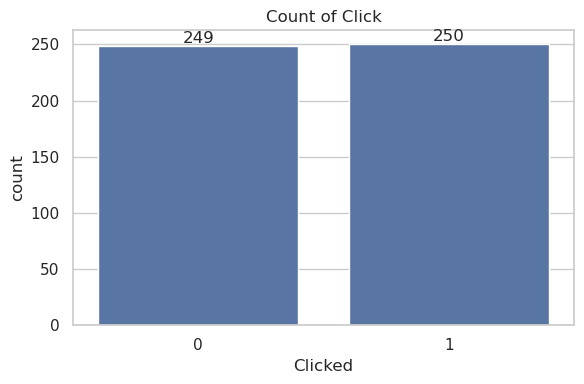

In [28]:
click = df[df[TARGET] == 1]
no_click = df[df[TARGET] == 0]

print("Total          =", len(df))
print("Clicked        =", len(click))
print("CTR            =", round(len(click) / len(df) * 100, 2), "%")
print("No click       =", len(no_click))
print("Non-click rate =", round(len(no_click) / len(df) * 100, 2), "%")

plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df, x=TARGET)

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f")
    
plt.title("Count of Click")
plt.tight_layout()
plt.show()

The dataset contains 499 observations: 250 users clicked on the ad (50.1%) and 249 did not (49.9%). The target classes are almost perfectly balanced. The near-50/50 split describes this specific dataset.

### Boxplot

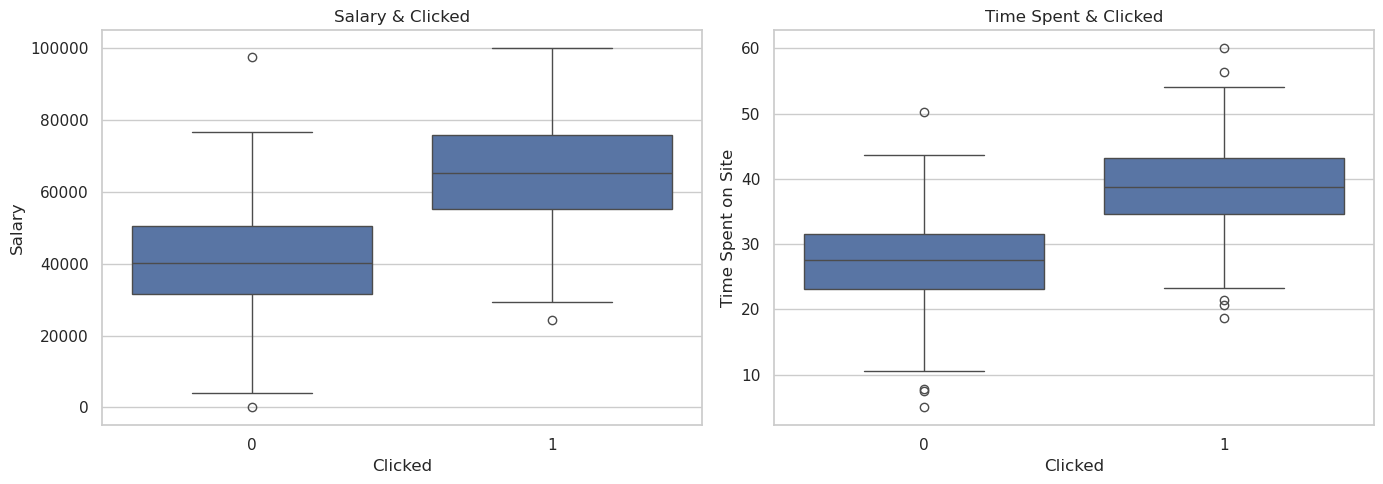

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(x=TARGET, y="Salary", data=df, ax=axes[0])
axes[0].set_title("Salary & Clicked")
sns.boxplot(x=TARGET, y="Time Spent on Site", data=df, ax=axes[1])
axes[1].set_title("Time Spent & Clicked")
plt.tight_layout()
plt.show()

Salary & Clicked and Time Spent & Clicked Distributions
The box plots illustrate the distribution of Salary and Time Spent on Site grouped by the target class (Clicked).
Users who clicked on the ad (Clicked = 1) display noticeably higher median values for both features compared to those who did not (Clicked = 0). Specifically, the median salary for users who clicked is around 65,000 (versus 40,000 for non-clickers), and their median time spent on the site is approximately 38 minutes (versus 28 minutes). Both features demonstrate clear separation between the two classes, making them strong predictors for the classification model.

### Scatterplot

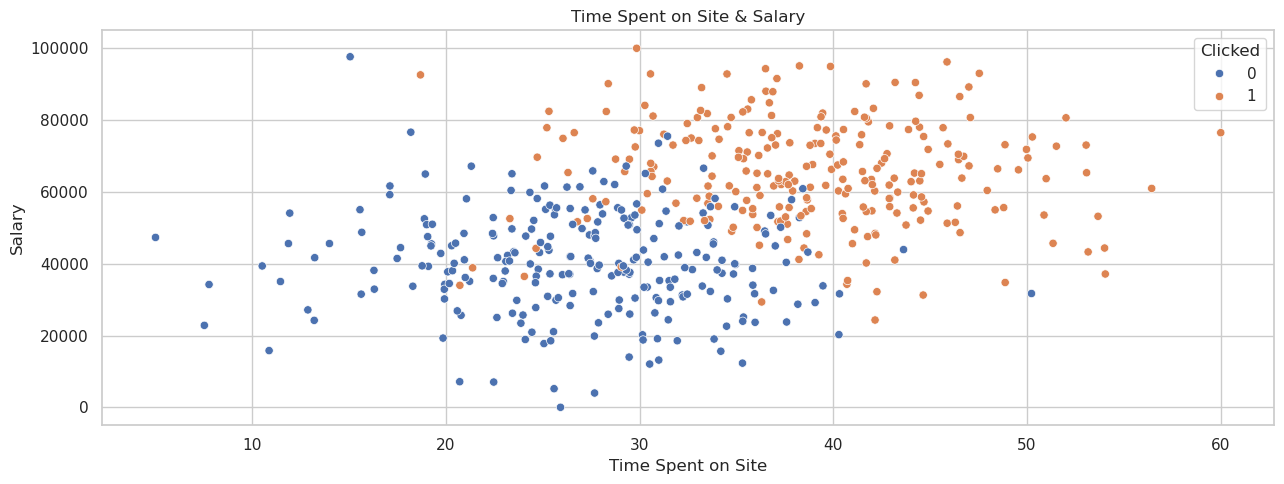

In [30]:
plt.figure(figsize=(13, 5))
sns.scatterplot(x="Time Spent on Site", y="Salary", hue=TARGET, data=df)
plt.title("Time Spent on Site & Salary")
plt.tight_layout()
plt.show()

Joint Distribution of Time Spent on Site and Salary
The scatterplot illustrates the joint distribution of Time Spent on Site and Salary, color-coded by the target variable Clicked.
There is a clear visual separation between the two classes: users who clicked on the ad (Clicked = 1, orange) tend to have both higher salaries and spend more time on the site, clustering in the upper-right quadrant of the plot. Conversely, non-clickers (Clicked = 0, blue) accumulate in the lower-left area. This distinct spatial segregation confirms that combining these two features provides strong predictive power for determining ad-clicking behavior.

### Distributions and correlations

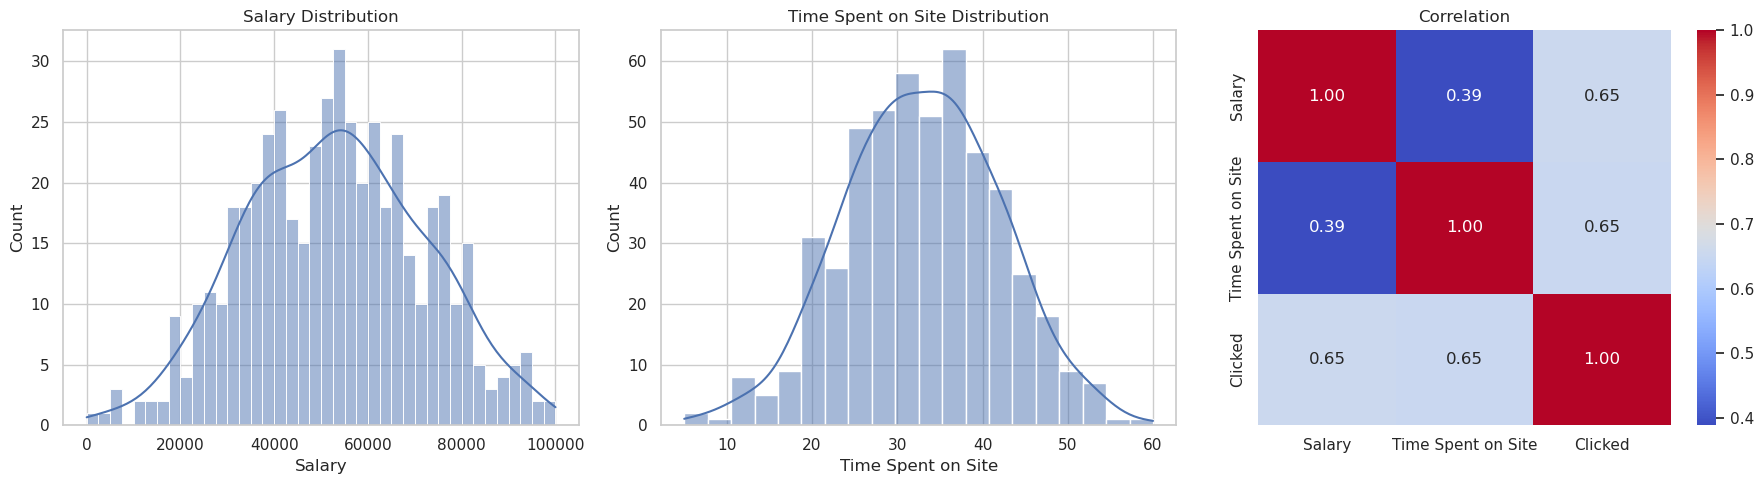

In [31]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.histplot(df["Salary"], bins=40, kde=True, ax=axes[0])
axes[0].set_title("Salary Distribution")
sns.histplot(df["Time Spent on Site"], bins=20, kde=True, ax=axes[1])
axes[1].set_title("Time Spent on Site Distribution")
sns.heatmap(df[["Salary", "Time Spent on Site", TARGET]].corr(), annot=True, fmt=".2f",
            cmap="coolwarm", ax=axes[2])
axes[2].set_title("Correlation")
plt.tight_layout()
plt.show()

Exploratory Data Analysis:
Feature Distributions and Correlation AnalysisSalary Distribution: The continuous feature Salary exhibits a bell-shaped distribution close to normal, spanning from 0 to 100,000 with a central peak around 50,000–60,000.Time Spent on Site Distribution: Similarly, Time Spent on Site follows a near-normal distribution ranging between 5 and 60 minutes, centered around 30–35 minutes.   

Correlation Matrix:
The pairwise linear correlation between Salary and Time Spent on Site is moderate (r = 0.39), suggesting low risk of multicollinearity. Both features display strong positive linear correlations with the target variable Clicked (r = 0.65 for each feature), indicating that higher values in either feature are strongly associated with higher ad-clicking propensity.   

## 5. Train / test split

In [32]:
FEATURES = [c for c in df.columns if c not in DROP_COLUMNS + [TARGET]]
print("Features:", FEATURES)

X = df[FEATURES]
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_STATE, stratify=y
)

X_train.shape, X_test.shape

Features: ['Time Spent on Site', 'Salary']


((349, 2), (150, 2))

## 6. Pipelines

In [33]:
def make_scaled_pipe(model):
    return Pipeline([
        ("winsorizer", Winsorizer(capping_method="gaussian", tail="both", fold=3)),
        ("scaler", StandardScaler()),
        ("model", model),
    ])


def make_tree_pipe(model):
    return Pipeline([("model", model)])

## 7. Baseline models (cross-validation on train only)

In [34]:
baseline_models = {
    "Dummy": DummyClassifier(strategy="prior"),
    "LogReg": make_scaled_pipe(LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    "KNN": make_scaled_pipe(KNeighborsClassifier(n_neighbors=5)),
    "SVC": make_scaled_pipe(SVC(probability=True, random_state=RANDOM_STATE)),
    "AdaBoost": make_tree_pipe(AdaBoostClassifier(n_estimators=100, random_state=RANDOM_STATE)),
    "RandomForest": make_tree_pipe(RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE)),
}

rows = []
for name, model in baseline_models.items():
    cv = cross_validate(model, X_train, y_train, cv=TUNE_CV, n_jobs=-1,
                        scoring={"roc_auc": "roc_auc", "accuracy": "accuracy", "f1": "f1"})
    rows.append({
        "Model": name,
        "CV ROC-AUC": cv["test_roc_auc"].mean(),
        "CV ROC-AUC std": cv["test_roc_auc"].std(),
        "CV Accuracy": cv["test_accuracy"].mean(),
        "CV F1": cv["test_f1"].mean(),
    })

baseline_results = pd.DataFrame(rows).set_index("Model")
display(baseline_results.round(4))

,CV ROC-AUC,CV ROC-AUC std,CV Accuracy,CV F1
Model,,,,
Dummy,0.5000,0.0000,0.4986,0.5333
LogReg,0.9613,0.0157,0.8968,0.8978
KNN,0.9333,0.0193,0.8625,0.8628
SVC,0.9518,0.0208,0.8854,0.8857
AdaBoost,0.9515,0.0295,0.8855,0.8820
RandomForest,0.9511,0.0197,0.8769,0.8775


## 8. Hyperparametr Tuning

In [35]:
search_configs = {
    "LogReg": (
        make_scaled_pipe(LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
        {"model__C": loguniform(1e-2, 1e2)},
        20,
    ),
    "KNN": (
        make_scaled_pipe(KNeighborsClassifier()),
        {"model__n_neighbors": randint(1, 30),
         "model__weights": ["uniform", "distance"],
         "model__p": [1, 2]},
        20,
    ),
    "SVC": (
        make_scaled_pipe(SVC(probability=True, random_state=RANDOM_STATE)),
        {"model__C": loguniform(1e-1, 1e2),
         "model__gamma": loguniform(1e-3, 1e0),
         "model__kernel": ["rbf"]},
        30,
    ),
    "AdaBoost": (
        make_tree_pipe(AdaBoostClassifier(random_state=RANDOM_STATE)),
        {"model__n_estimators": randint(50, 200),
         "model__learning_rate": uniform(0.01, 0.99)},
        30,
    ),
    "RandomForest": (
        make_tree_pipe(RandomForestClassifier(random_state=RANDOM_STATE)),
        {"model__n_estimators": randint(50, 200),
         "model__max_depth": randint(3, 15),
         "model__criterion": ["gini", "entropy"]},
        20,
    ),
}

searches = {}
for name, (pipe, param_dist, n_iter) in search_configs.items():
    search = RandomizedSearchCV(
        pipe, param_dist, n_iter=n_iter, cv=TUNE_CV, scoring=SCORING,
        random_state=RANDOM_STATE, n_jobs=-1,
    )
    search.fit(X_train, y_train)
    searches[name] = search
    print(f"{name:13s} best CV ROC-AUC = {search.best_score_:.4f} | {search.best_params_}")

LogReg        best CV ROC-AUC = 0.9638 | {'model__C': np.float64(0.017073967431528128)}
KNN           best CV ROC-AUC = 0.9604 | {'model__n_neighbors': 25, 'model__p': 1, 'model__weights': 'uniform'}
SVC           best CV ROC-AUC = 0.9643 | {'model__C': np.float64(0.18427970406864538), 'model__gamma': np.float64(0.0038721180321745824), 'model__kernel': 'rbf'}
AdaBoost      best CV ROC-AUC = 0.9520 | {'model__learning_rate': np.float64(0.40586236199810294), 'model__n_estimators': 64}
RandomForest  best CV ROC-AUC = 0.9543 | {'model__criterion': 'gini', 'model__max_depth': 4, 'model__n_estimators': 181}


## 9. StackingClassifier

In [36]:
stacking_clf = StackingClassifier(
    estimators=[(name.lower(), clone(searches[name].best_estimator_))
                for name in ["KNN", "SVC", "AdaBoost", "RandomForest"]],
    final_estimator=LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
)

tuned_models = {name: clone(s.best_estimator_) for name, s in searches.items()}
tuned_models["Stacking"] = stacking_clf
list(tuned_models)

['LogReg', 'KNN', 'SVC', 'AdaBoost', 'RandomForest', 'Stacking']

## 10. Model selection by cross-validation 

,Mean ROC-AUC,Std
Model,,
LogReg,0.9630,0.0194
KNN,0.9601,0.0204
SVC,0.9635,0.0195
AdaBoost,0.9567,0.0250
RandomForest,0.9562,0.0222
Stacking,0.9615,0.0208


Highest mean CV ROC-AUC : SVC (0.9635)
Selected (1-SE rule)    : LogReg (0.9630)


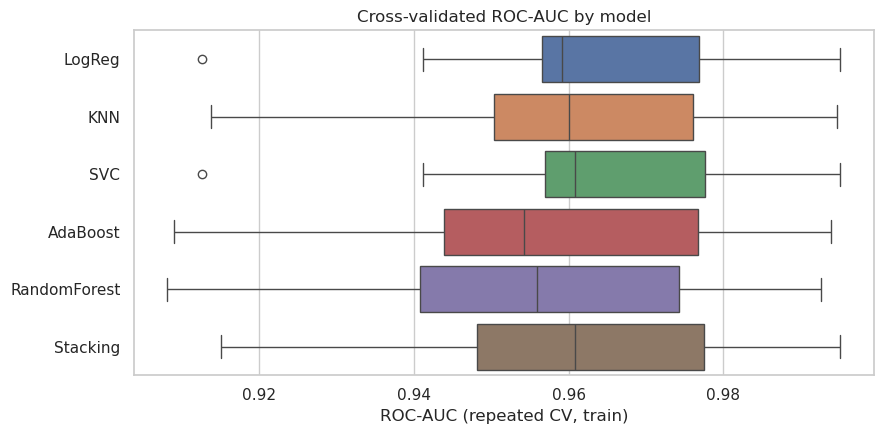

In [37]:
COMPLEXITY_ORDER = ["LogReg", "KNN", "SVC", "AdaBoost", "RandomForest", "Stacking"]

cv_rows = []
cv_scores = {}
for name in COMPLEXITY_ORDER:
    scores = cross_val_score(tuned_models[name], X_train, y_train,
                             cv=EVAL_CV, scoring=SCORING, n_jobs=-1)
    cv_scores[name] = scores
    cv_rows.append({"Model": name, "Mean ROC-AUC": scores.mean(), "Std": scores.std()})

cv_results = pd.DataFrame(cv_rows).set_index("Model")
display(cv_results.round(4))

top_name = cv_results["Mean ROC-AUC"].idxmax()
threshold = cv_results.loc[top_name, "Mean ROC-AUC"] - cv_results.loc[top_name, "Std"]
selected_name = next(n for n in COMPLEXITY_ORDER if cv_results.loc[n, "Mean ROC-AUC"] >= threshold)

print(f"Highest mean CV ROC-AUC : {top_name} ({cv_results.loc[top_name, 'Mean ROC-AUC']:.4f})")
print(f"Selected (1-SE rule)    : {selected_name} ({cv_results.loc[selected_name, 'Mean ROC-AUC']:.4f})")

plt.figure(figsize=(9, 4.5))
sns.boxplot(data=pd.DataFrame(cv_scores), orient="h")
plt.xlabel("ROC-AUC (repeated CV, train)")
plt.title("Cross-validated ROC-AUC by model")
plt.tight_layout()
plt.show()

## 11. Final evaluation on the test set

In [38]:
fitted_models = {name: clone(model).fit(X_train, y_train) for name, model in tuned_models.items()}
fitted_models["Dummy"] = clone(baseline_models["Dummy"]).fit(X_train, y_train)

def evaluate_model(name, model):
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "F1-Score": f1_score(y_test, y_pred, zero_division=0),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_proba),
        "PR-AUC": average_precision_score(y_test, y_proba),
    }

results = pd.DataFrame(
    [evaluate_model(n, fitted_models[n]) for n in ["Dummy"] + COMPLEXITY_ORDER]
).set_index("Model")

display(results.round(4).style.apply(
    lambda row: ["background-color: lightblue; font-weight: bold" if row.name == selected_name else "" for _ in row], axis=1
))
print(f"Selected model: {selected_name}")

,Accuracy,F1-Score,Precision,Recall,ROC-AUC,PR-AUC
Model,,,,,,
Dummy,0.500000,0.666700,0.500000,1.000000,0.500000,0.500000
LogReg,0.946700,0.946700,0.946700,0.946700,0.963700,0.973900
KNN,0.940000,0.940400,0.934200,0.946700,0.964500,0.969500
SVC,0.946700,0.947400,0.935100,0.960000,0.963400,0.973500
AdaBoost,0.933300,0.931500,0.957700,0.906700,0.952500,0.961400
RandomForest,0.940000,0.940400,0.934200,0.946700,0.950700,0.964100
Stacking,0.946700,0.947400,0.935100,0.960000,0.960400,0.972100


Selected model: LogReg


### Confidence interval for the selected model

In [39]:
selected_model = fitted_models[selected_name]
y_proba_sel = selected_model.predict_proba(X_test)[:, 1]
y_test_arr = y_test.to_numpy()

rng = np.random.default_rng(RANDOM_STATE)
boot_auc = []
for _ in range(2000):
    idx = rng.integers(0, len(y_test_arr), len(y_test_arr))
    if len(np.unique(y_test_arr[idx])) < 2:
        continue
    boot_auc.append(roc_auc_score(y_test_arr[idx], y_proba_sel[idx]))

ci_low, ci_high = np.percentile(boot_auc, [2.5, 97.5])
print(f"{selected_name}: test ROC-AUC = {roc_auc_score(y_test, y_proba_sel):.4f} "
      f"(95% bootstrap CI: {ci_low:.4f} – {ci_high:.4f})")

LogReg: test ROC-AUC = 0.9637 (95% bootstrap CI: 0.9300 – 0.9920)


## 12. Classification reports

In [40]:
for name in COMPLEXITY_ORDER:
    print(f"\n{'=' * 60}\n{name}\n{'=' * 60}")
    print(classification_report(y_test, fitted_models[name].predict(X_test),
                                target_names=["No Click", "Click"], zero_division=0))


LogReg
              precision    recall  f1-score   support

    No Click       0.95      0.95      0.95        75
       Click       0.95      0.95      0.95        75

    accuracy                           0.95       150
   macro avg       0.95      0.95      0.95       150
weighted avg       0.95      0.95      0.95       150


KNN
              precision    recall  f1-score   support

    No Click       0.95      0.93      0.94        75
       Click       0.93      0.95      0.94        75

    accuracy                           0.94       150
   macro avg       0.94      0.94      0.94       150
weighted avg       0.94      0.94      0.94       150


SVC
              precision    recall  f1-score   support

    No Click       0.96      0.93      0.95        75
       Click       0.94      0.96      0.95        75

    accuracy                           0.95       150
   macro avg       0.95      0.95      0.95       150
weighted avg       0.95      0.95      0.95       150




## 13. Confusion matrices

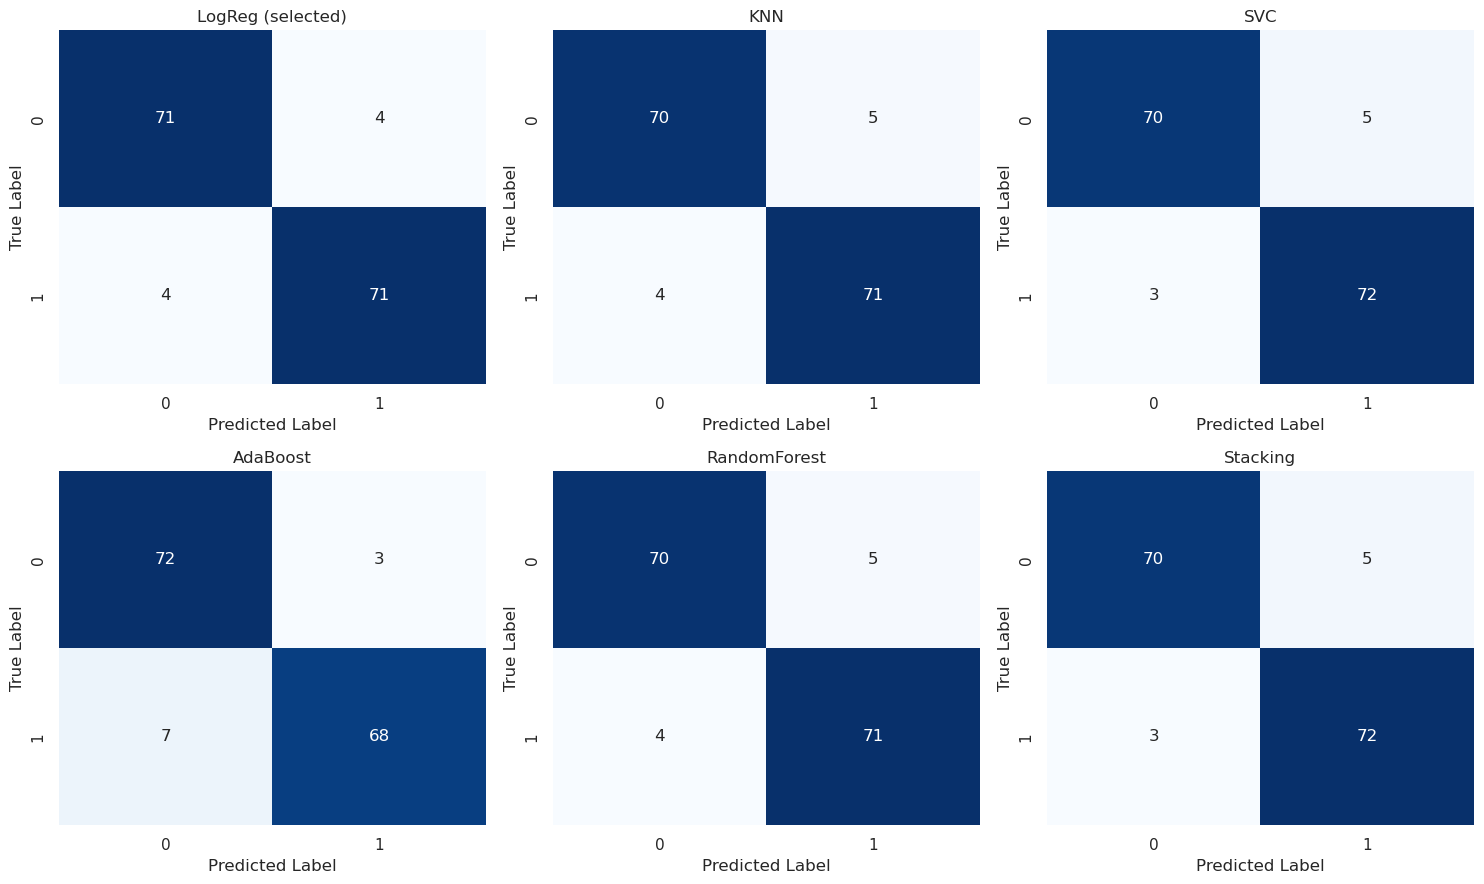

In [41]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, name in zip(axes.flatten(), COMPLEXITY_ORDER):
    cm = confusion_matrix(y_test, fitted_models[name].predict(X_test))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
    ax.set_title(name + (" (selected)" if name == selected_name else ""))
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("True Label")
plt.tight_layout()
plt.show()

## 14. ROC and Precision-Recall curves

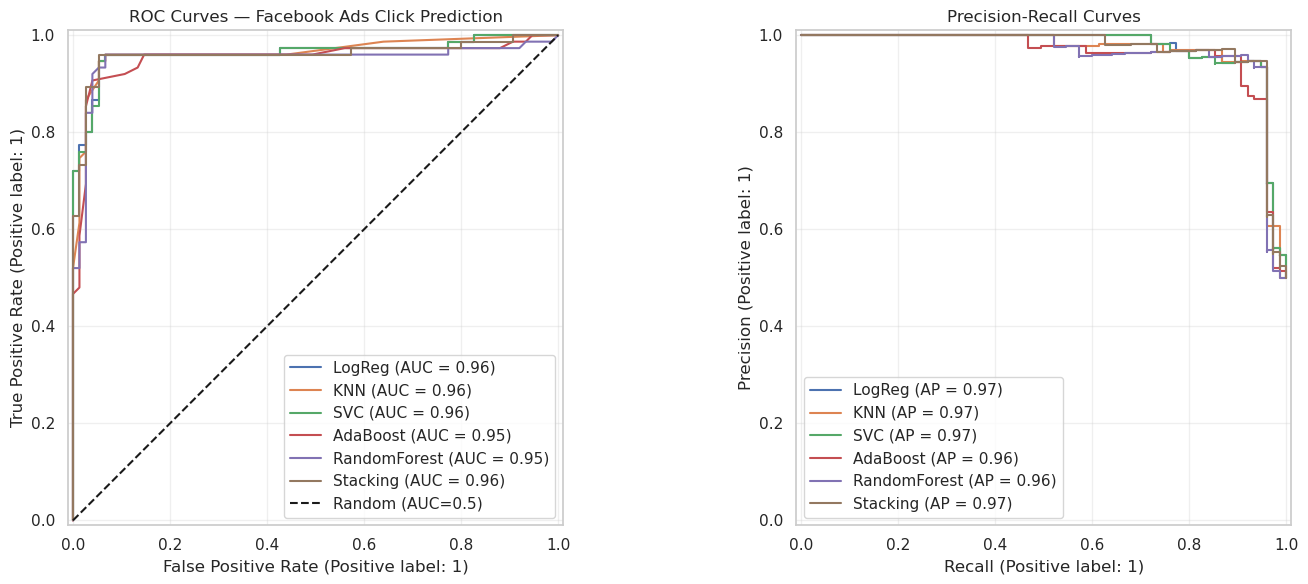

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for name in COMPLEXITY_ORDER:
    proba = fitted_models[name].predict_proba(X_test)[:, 1]
    RocCurveDisplay.from_predictions(y_test, proba, name=name, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_test, proba, name=name, ax=axes[1])

axes[0].plot([0, 1], [0, 1], "k--", label="Random (AUC=0.5)")
axes[0].set_title("ROC Curves — Facebook Ads Click Prediction")
axes[0].legend(loc="lower right")
axes[1].set_title("Precision-Recall Curves")
axes[1].legend(loc="lower left")
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 15. Metric comparison

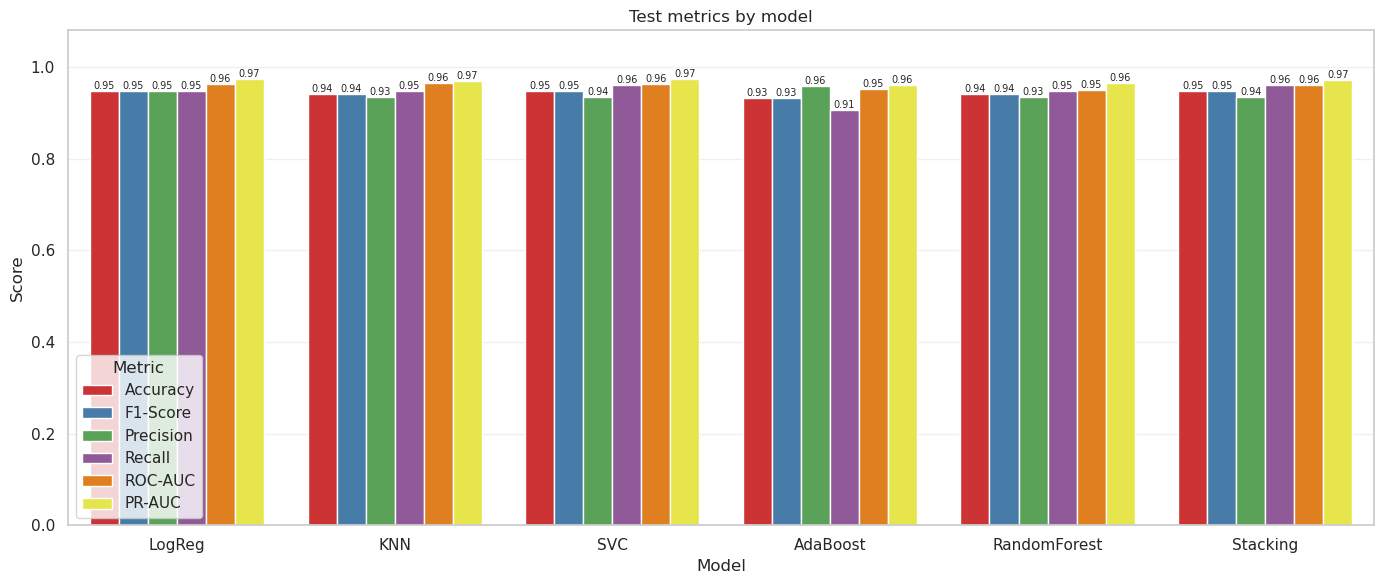

In [43]:
comparison = (results.drop(index="Dummy").reset_index()
              .melt(id_vars="Model", var_name="Metric", value_name="Score"))

plt.figure(figsize=(14, 6))
ax = sns.barplot(x="Model", y="Score", hue="Metric", data=comparison, palette="Set1")
for p in ax.patches:
    h = p.get_height()
    if not np.isnan(h) and h > 0:
        ax.annotate(f"{h:.2f}", (p.get_x() + p.get_width() / 2, h),
                    ha="center", va="bottom", fontsize=7)
plt.ylim(0, 1.08)
plt.title("Test metrics by model")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## 16. Feature importance 

,Feature,Importance,Std
1,Salary,0.2101,0.0333
0,Time Spent on Site,0.1929,0.0314


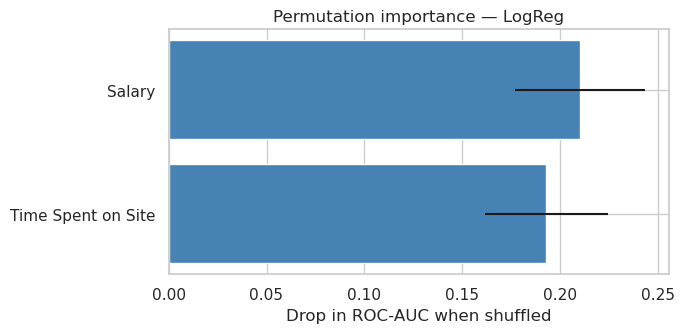

In [44]:
perm = permutation_importance(selected_model, X_test, y_test, scoring=SCORING,
                              n_repeats=30, random_state=RANDOM_STATE, n_jobs=-1)

importance = (pd.DataFrame({"Feature": FEATURES,
                            "Importance": perm.importances_mean,
                            "Std": perm.importances_std})
              .sort_values("Importance", ascending=False))
display(importance.round(4))

plt.figure(figsize=(7, 3.5))
plt.barh(importance["Feature"][::-1], importance["Importance"][::-1],
         xerr=importance["Std"][::-1], color="steelblue")
plt.xlabel("Drop in ROC-AUC when shuffled")
plt.title(f"Permutation importance — {selected_name}")
plt.tight_layout()
plt.show()

## 17. Final conclusion

In [45]:
print("Selected model:", selected_name)
print("CV ROC-AUC:", round(cv_results.loc[selected_name, "Mean ROC-AUC"], 3))
print("Test ROC-AUC:", round(results.loc[selected_name, "ROC-AUC"], 3))
print("95% CI:", round(ci_low, 3), "-", round(ci_high, 3))
print("Dummy baseline ROC-AUC:", round(results.loc["Dummy", "ROC-AUC"], 3))

print()
print("Stacking CV ROC-AUC:", round(cv_results.loc["Stacking", "Mean ROC-AUC"], 3))
print("Most important feature:", importance.iloc[0]["Feature"])

Selected model: LogReg
CV ROC-AUC: 0.963
Test ROC-AUC: 0.964
95% CI: 0.93 - 0.992
Dummy baseline ROC-AUC: 0.5

Stacking CV ROC-AUC: 0.961
Most important feature: Salary
